# TED Talks: Exploratory Data Analysis (EDA)
**Dataset:** TED - Ultimate Dataset (Kaggle)  
**Author:** Adhyayan  
**Objective:** Perform comprehensive exploratory data analysis to uncover trends, viewership patterns, speaker dynamics, talk duration distributions, and popular themes across TED talks.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from wordcloud import WordCloud
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

## 1. Loading Data & Quick Look

In [ ]:
# load the dataset
df = pd.read_csv('data/ted_talks_en.csv')
print(f"Shape of dataset: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Shape of dataset: 4005 rows, 19 columns


In [ ]:
# check column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_lang  4005 non-null   object 
 12  comments        3350 non-null   float64
 13  duration        4005 non-null   int64  
 14  topics          4005 non-null   object 
 15  related_talks   4005 non-null   object 
 16  url             4005 non-null   object 
 17  description     4005 non-null   o

## 2. Data Cleaning & Feature Extraction
- Check and inspect missing values
- Convert dates to datetime objects (`published_year`, `published_month`, `published_day_name`)
- Convert duration to minutes (`duration_min`)
- Parse list columns (`topics`, `available_lang`)
- Extract text features (`transcript_word_count`, `speaking_rate_wpm`)
- Calculate engagement ratio (`comments_per_1k_views`)

In [ ]:
# check missing values
df.isnull().sum()

talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64

In [ ]:
# date features
df['published_date'] = pd.to_datetime(df['published_date'], errors='coerce')
df['recorded_date'] = pd.to_datetime(df['recorded_date'], errors='coerce')
df['published_year'] = df['published_date'].dt.year
df['published_month'] = df['published_date'].dt.month
df['published_day_name'] = df['published_date'].dt.day_name()

# duration in minutes
df['duration_min'] = df['duration'] / 60.0

# parse list columns
def parse_list(x):
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return []
    return []

df['topics_list'] = df['topics'].apply(parse_list)
df['available_lang_list'] = df['available_lang'].apply(parse_list)

df['num_topics'] = df['topics_list'].apply(len)
df['num_languages'] = df['available_lang_list'].apply(len)

# text stats and speaking rate
df['transcript_word_count'] = df['transcript'].fillna('').apply(lambda x: len(str(x).split()))
df['speaking_rate_wpm'] = df['transcript_word_count'] / df['duration_min']
df['speaking_rate_wpm'] = df['speaking_rate_wpm'].replace([np.inf, -np.inf], np.nan)

# engagement metrics
df['comments_per_1k_views'] = (df['comments'] / df['views']) * 1000

df[['views', 'comments', 'duration_min', 'num_languages', 'speaking_rate_wpm']].describe()

              views     comments  duration_min  num_languages  speaking_rate_wpm
count  4.005000e+03  3350.000000   4005.000000    4005.000000        4005.000000
mean   2.148006e+06   161.997015     12.066854      25.304120         147.428011
std    3.451226e+06   268.838922      6.029591       9.038567          27.178778
min    0.000000e+00     0.000000      1.000000       1.000000           0.203390
25%    8.820690e+05    38.000000      6.550000      20.000000         134.067995
50%    1.375508e+06    89.000000     12.300000      25.000000         148.032787
75%    2.133110e+06   188.000000     16.233333      31.000000         164.221636
max    6.505195e+07  6449.000000     65.366667      73.000000         244.864865


## 3. Most Popular Talks & Speakers

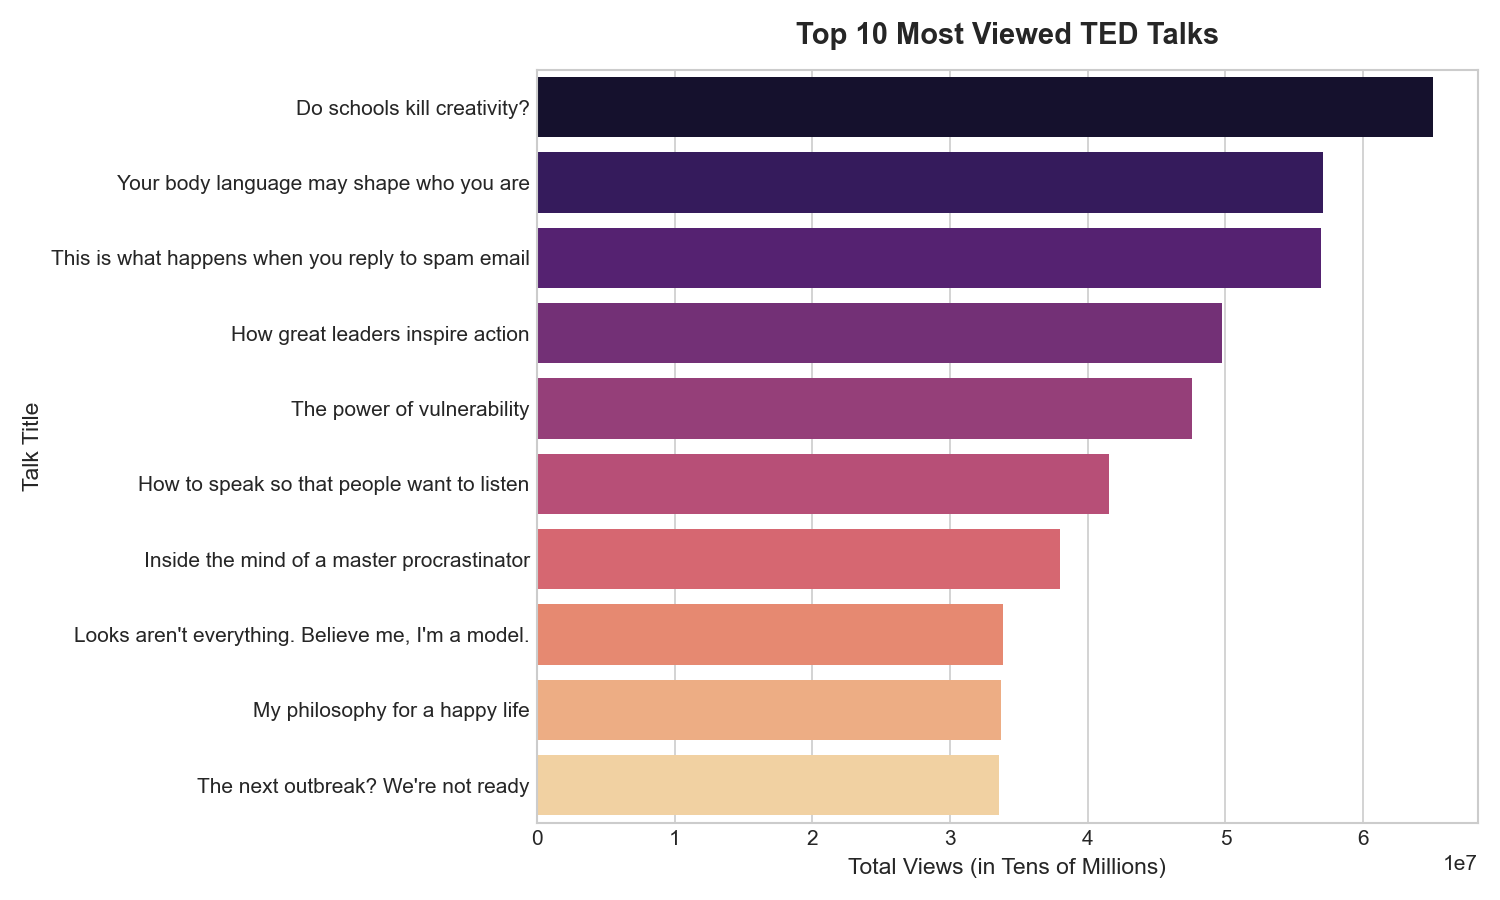

In [ ]:
# top 10 most viewed talks
top10_views = df.sort_values(by='views', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=top10_views, x='views', y='title', palette='magma')
plt.title('Top 10 Most Viewed TED Talks', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Views')
plt.ylabel('Title')
plt.tight_layout()
plt.show()

### Top Speakers by Total Views

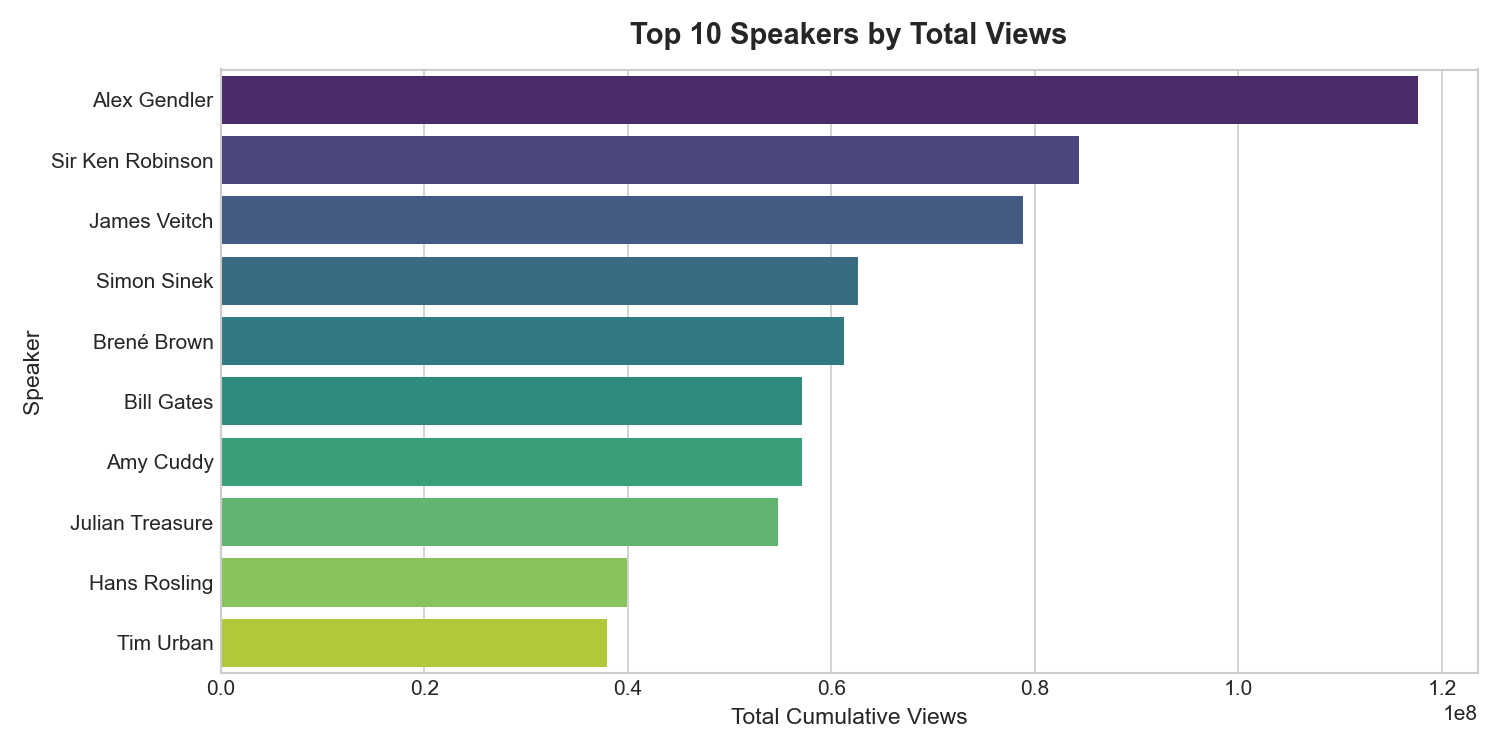

In [ ]:
# top 10 speakers by views
top_speakers_views = df.groupby('speaker_1')['views'].sum().sort_values(ascending=False).head(10).reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=top_speakers_views, x='views', y='speaker_1', palette='viridis')
plt.title('Top 10 Speakers by Total Views', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Views')
plt.ylabel('Speaker')
plt.tight_layout()
plt.show()

### Most Frequent Speakers

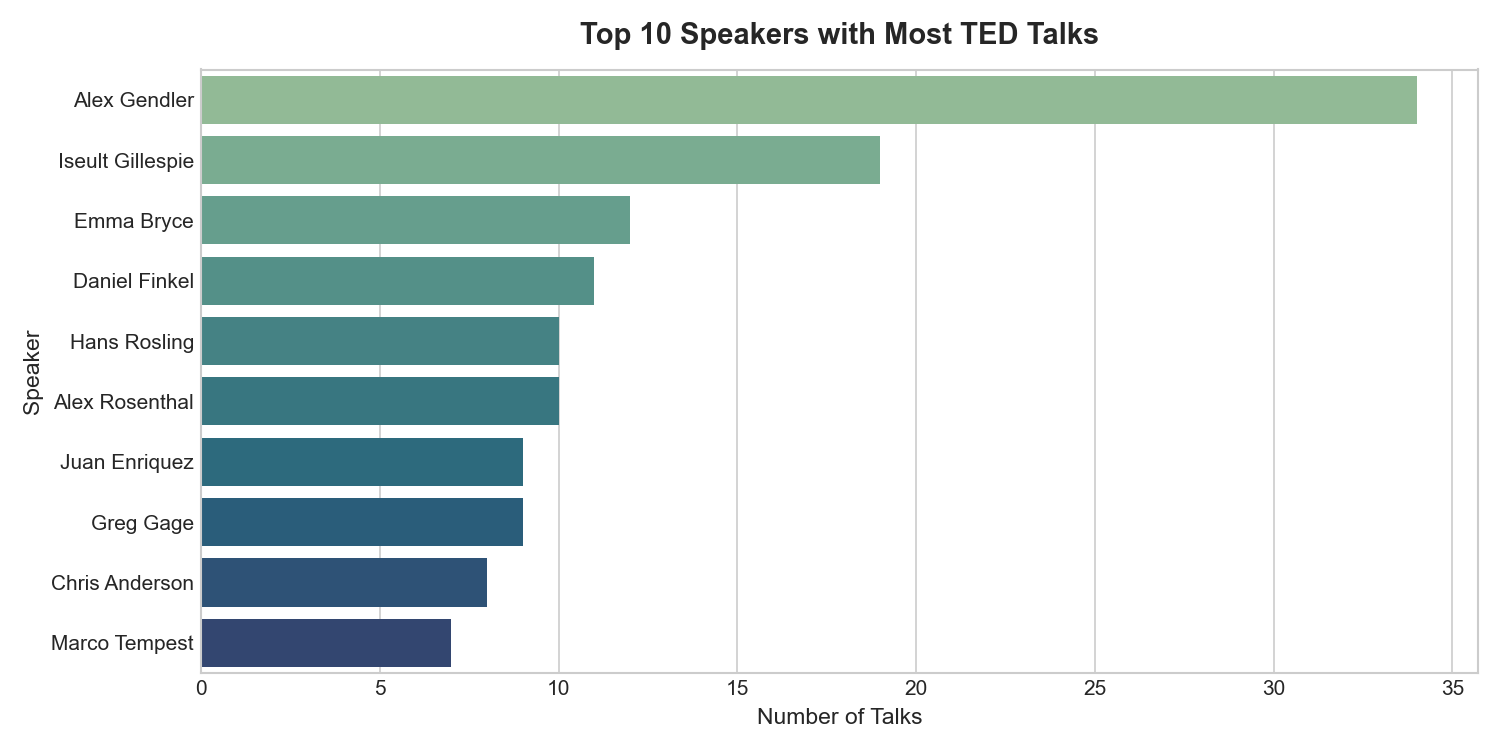

In [ ]:
# top speakers by number of talks
top_speakers_talks = df['speaker_1'].value_counts().head(10).reset_index()
top_speakers_talks.columns = ['speaker_1', 'talk_count']
plt.figure(figsize=(10, 5))
sns.barplot(data=top_speakers_talks, x='talk_count', y='speaker_1', palette='crest')
plt.title('Top 10 Speakers with Most TED Talks', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Talks')
plt.ylabel('Speaker')
plt.tight_layout()
plt.show()

## 4. Distributions of Views, Duration & Comments

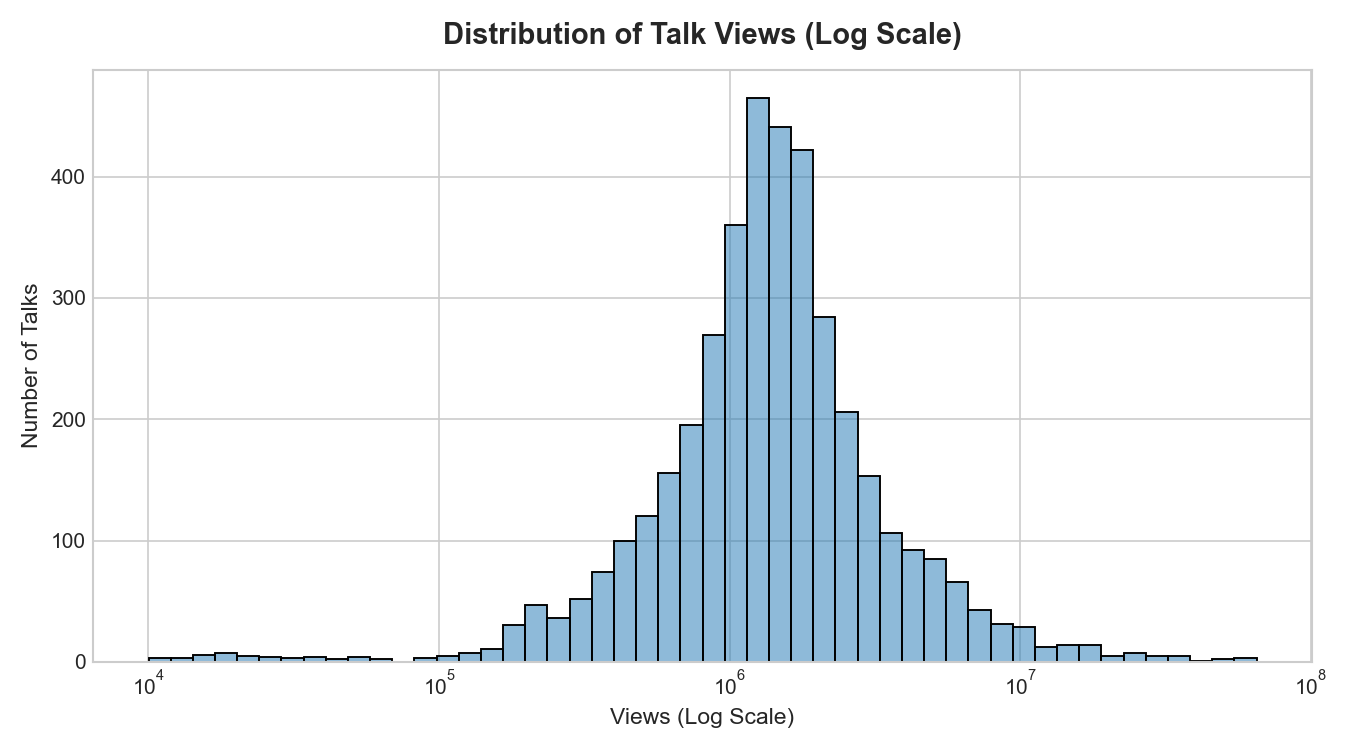

In [ ]:
# distribution of views (log scale)
plt.figure(figsize=(9, 5))
sns.histplot(df['views'], bins=50, kde=True, color='#1f77b4', log_scale=True)
plt.title('Distribution of Talk Views (Log Scale)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Views (Log Scale)')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

### Talk Duration Distribution

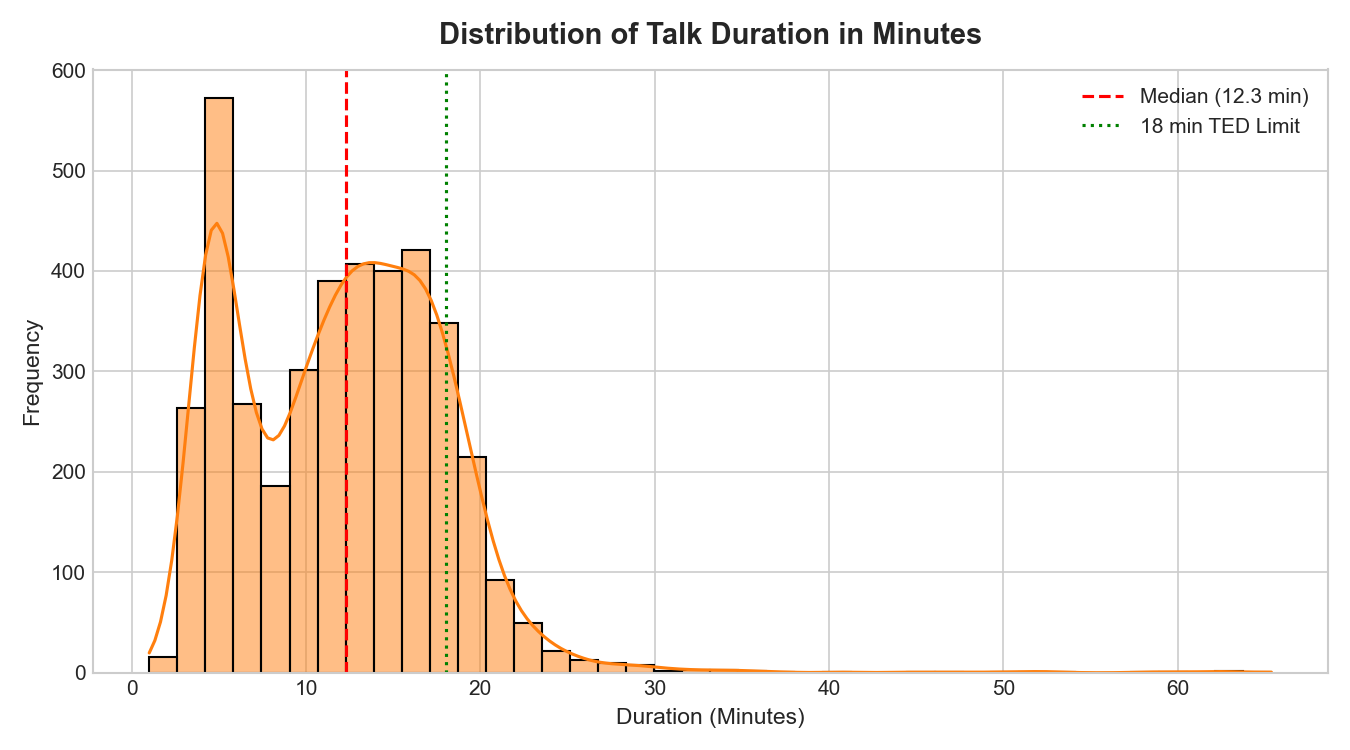

In [ ]:
# duration distribution
plt.figure(figsize=(9, 5))
sns.histplot(df['duration_min'], bins=40, kde=True, color='#ff7f0e')
plt.axvline(df['duration_min'].median(), color='red', linestyle='--', label=f'Median: {df["duration_min"].median():.1f} min')
plt.axvline(18, color='green', linestyle=':', label='18 min TED Limit')
plt.title('Distribution of Talk Duration in Minutes', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Duration (Minutes)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Engagement: Comments vs Views

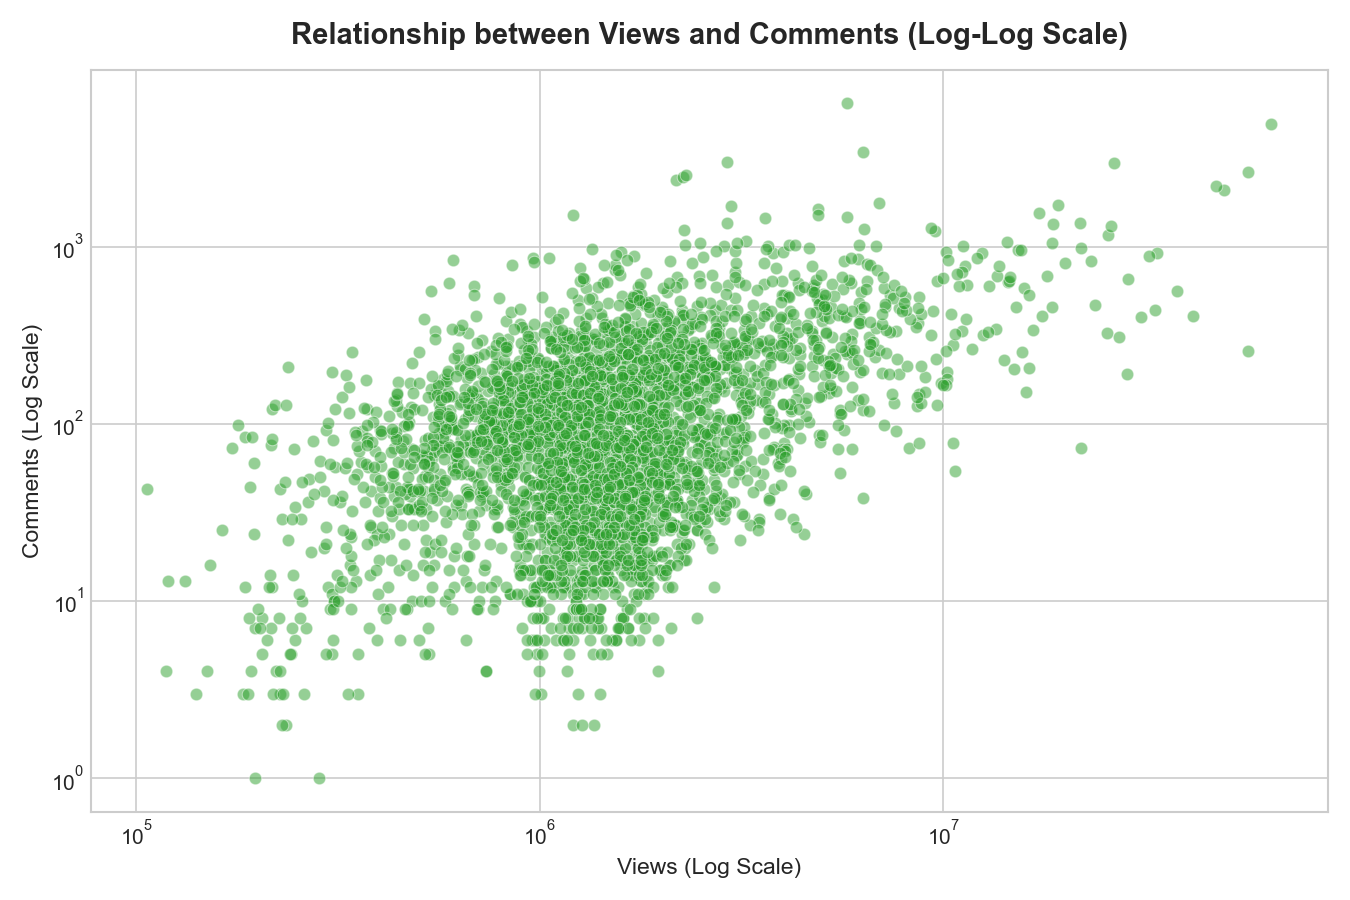

In [ ]:
# comments vs views scatter
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='views', y='comments', alpha=0.5, color='#2ca02c')
plt.xscale('log')
plt.yscale('log')
plt.title('Relationship between Views and Comments (Log-Log Scale)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Views (Log Scale)')
plt.ylabel('Comments (Log Scale)')
plt.tight_layout()
plt.show()

## 5. Temporal & Publishing Trends

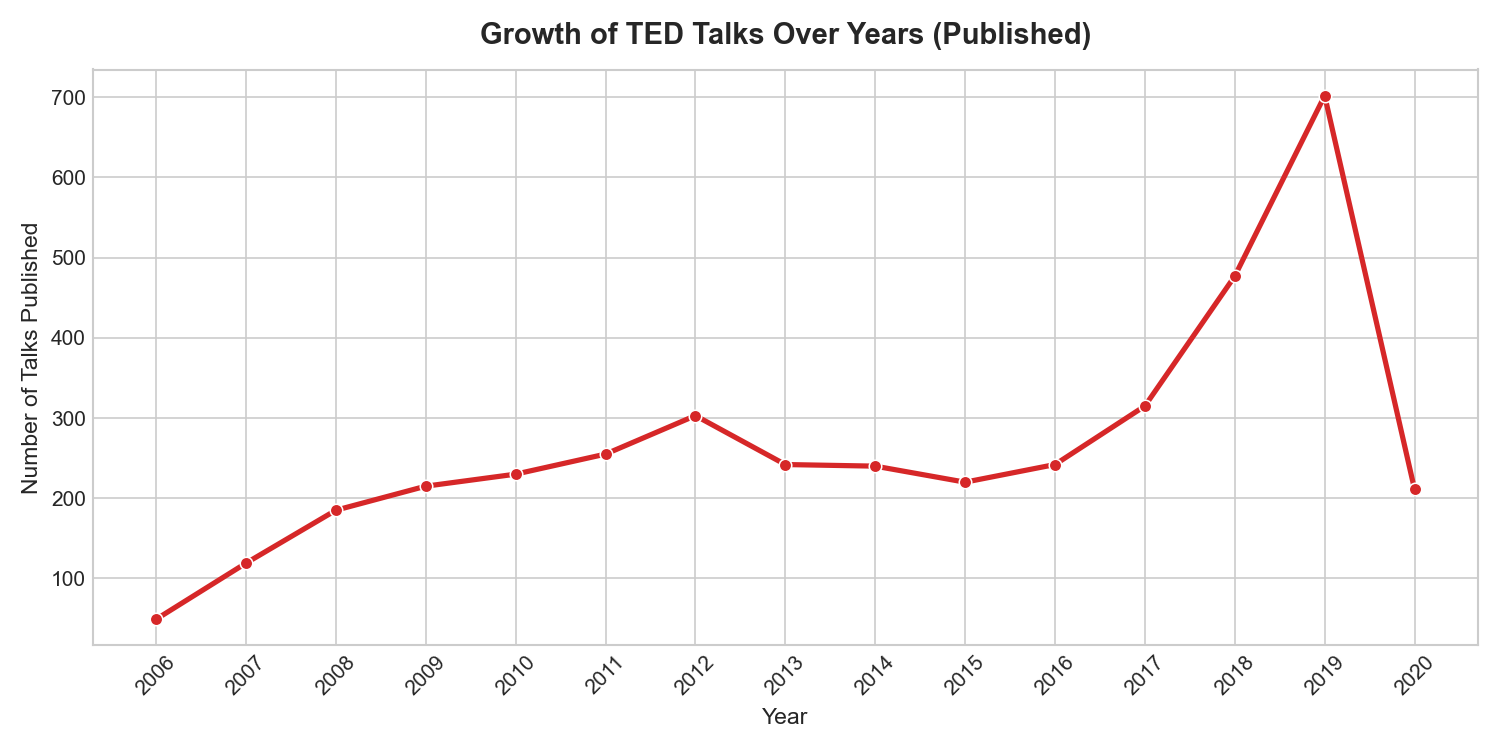

In [ ]:
# talks published per year
yearly = df['published_year'].value_counts().sort_index()
plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly.index, y=yearly.values, marker='o', color='#d62728', linewidth=2.5)
plt.title('Growth of TED Talks Over Years (Published)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Year')
plt.ylabel('Number of Talks')
plt.xticks(yearly.index, rotation=45)
plt.tight_layout()
plt.show()

### Average Views by Year

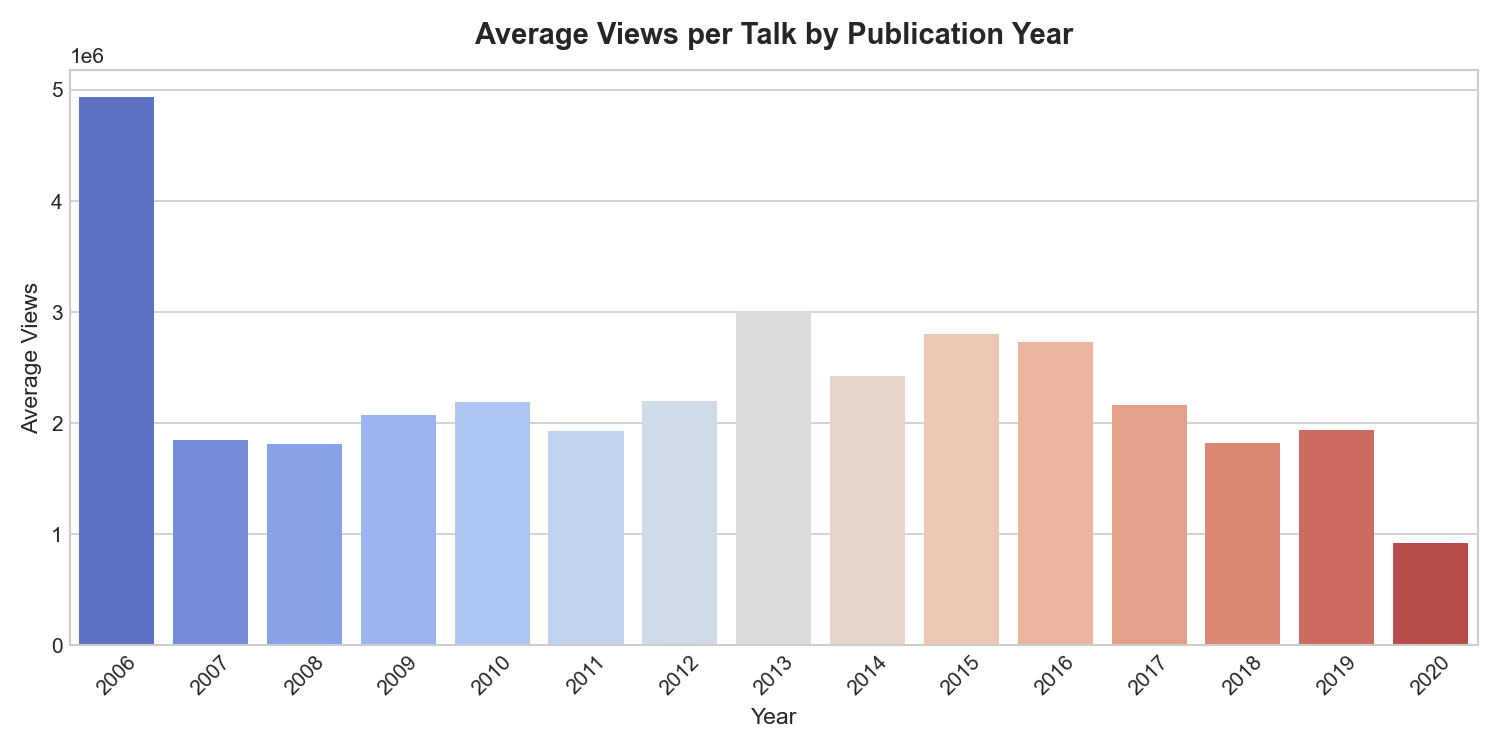

In [ ]:
# average views by publishing year
avg_views_year = df.groupby('published_year')['views'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=avg_views_year, x='published_year', y='views', palette='coolwarm')
plt.title('Average Views per Talk by Publication Year', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Year')
plt.ylabel('Average Views')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Publishing Day of the Week

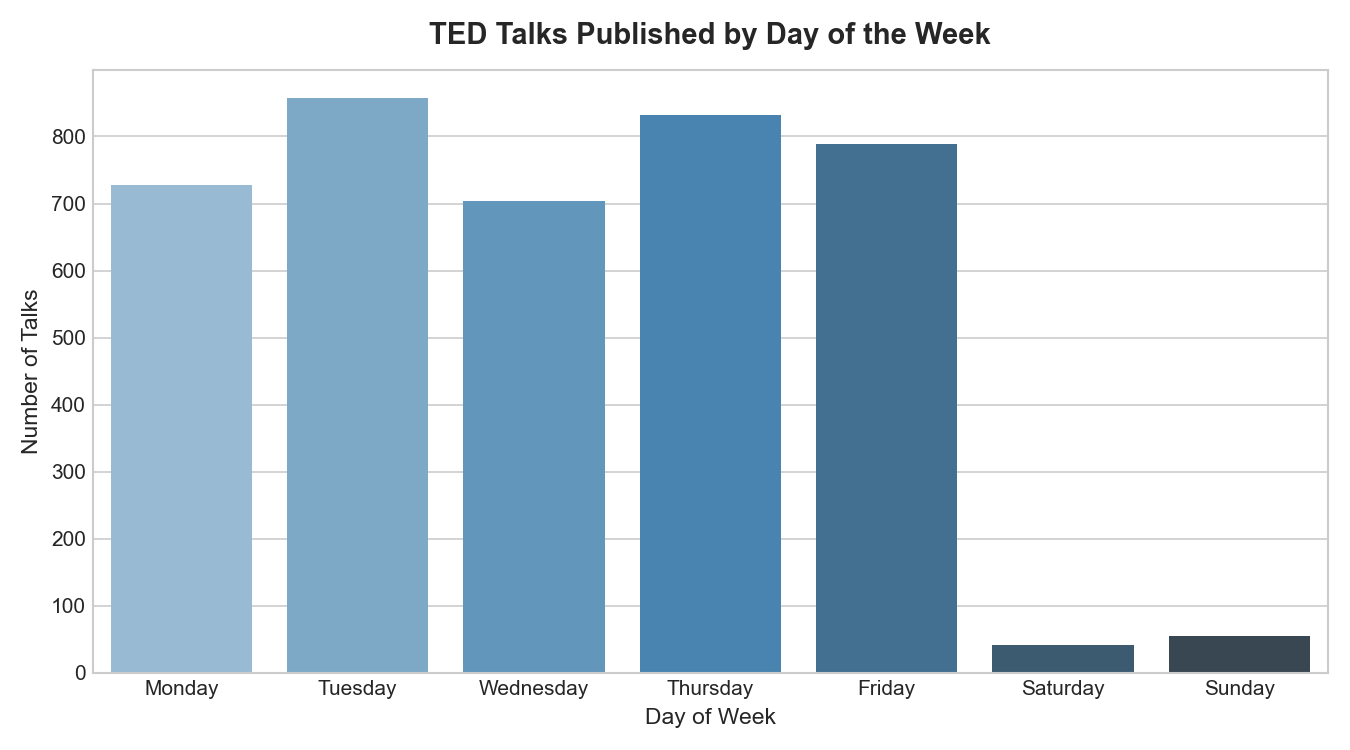

In [ ]:
# day of week distribution
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['published_day_name'].value_counts().reindex(day_order)
plt.figure(figsize=(9, 5))
sns.barplot(x=day_counts.index, y=day_counts.values, palette='Blues_d')
plt.title('TED Talks Published by Day of the Week', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 6. Topic & Theme Analysis

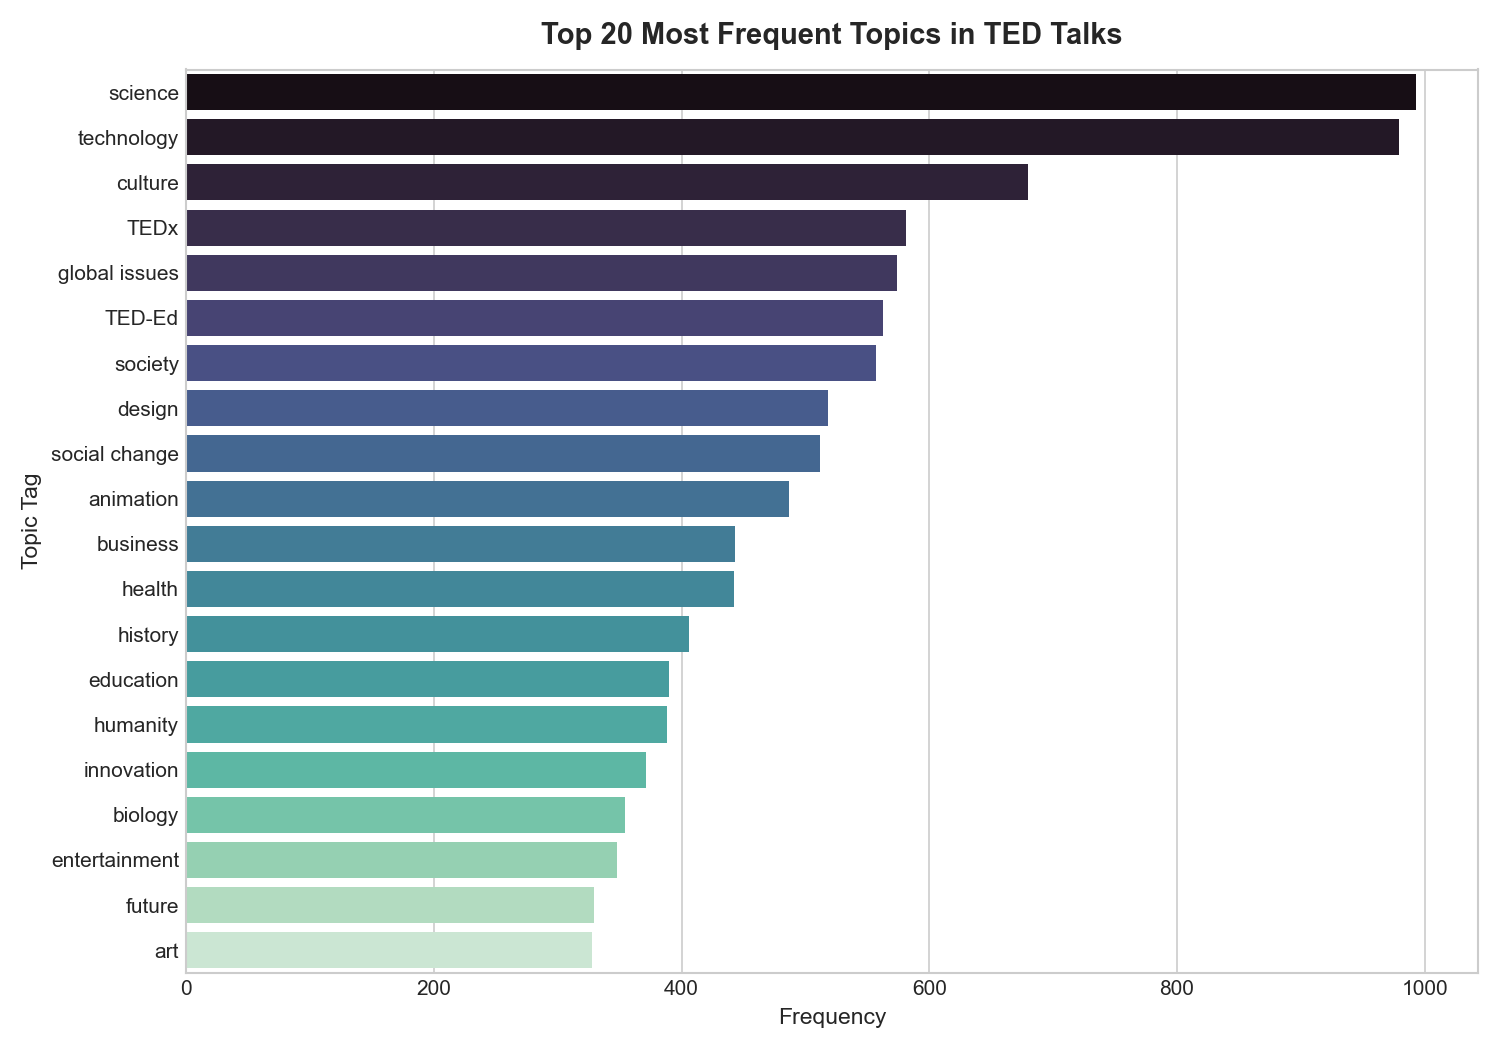

In [ ]:
# top 20 topics
all_topics = [t for sublist in df['topics_list'] for t in sublist]
topics_series = pd.Series(all_topics).value_counts().head(20)
plt.figure(figsize=(10, 7))
sns.barplot(x=topics_series.values, y=topics_series.index, palette='mako')
plt.title('Top 20 Most Frequent Topics in TED Talks', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Frequency')
plt.ylabel('Topic Tag')
plt.tight_layout()
plt.show()

### Topics Word Cloud

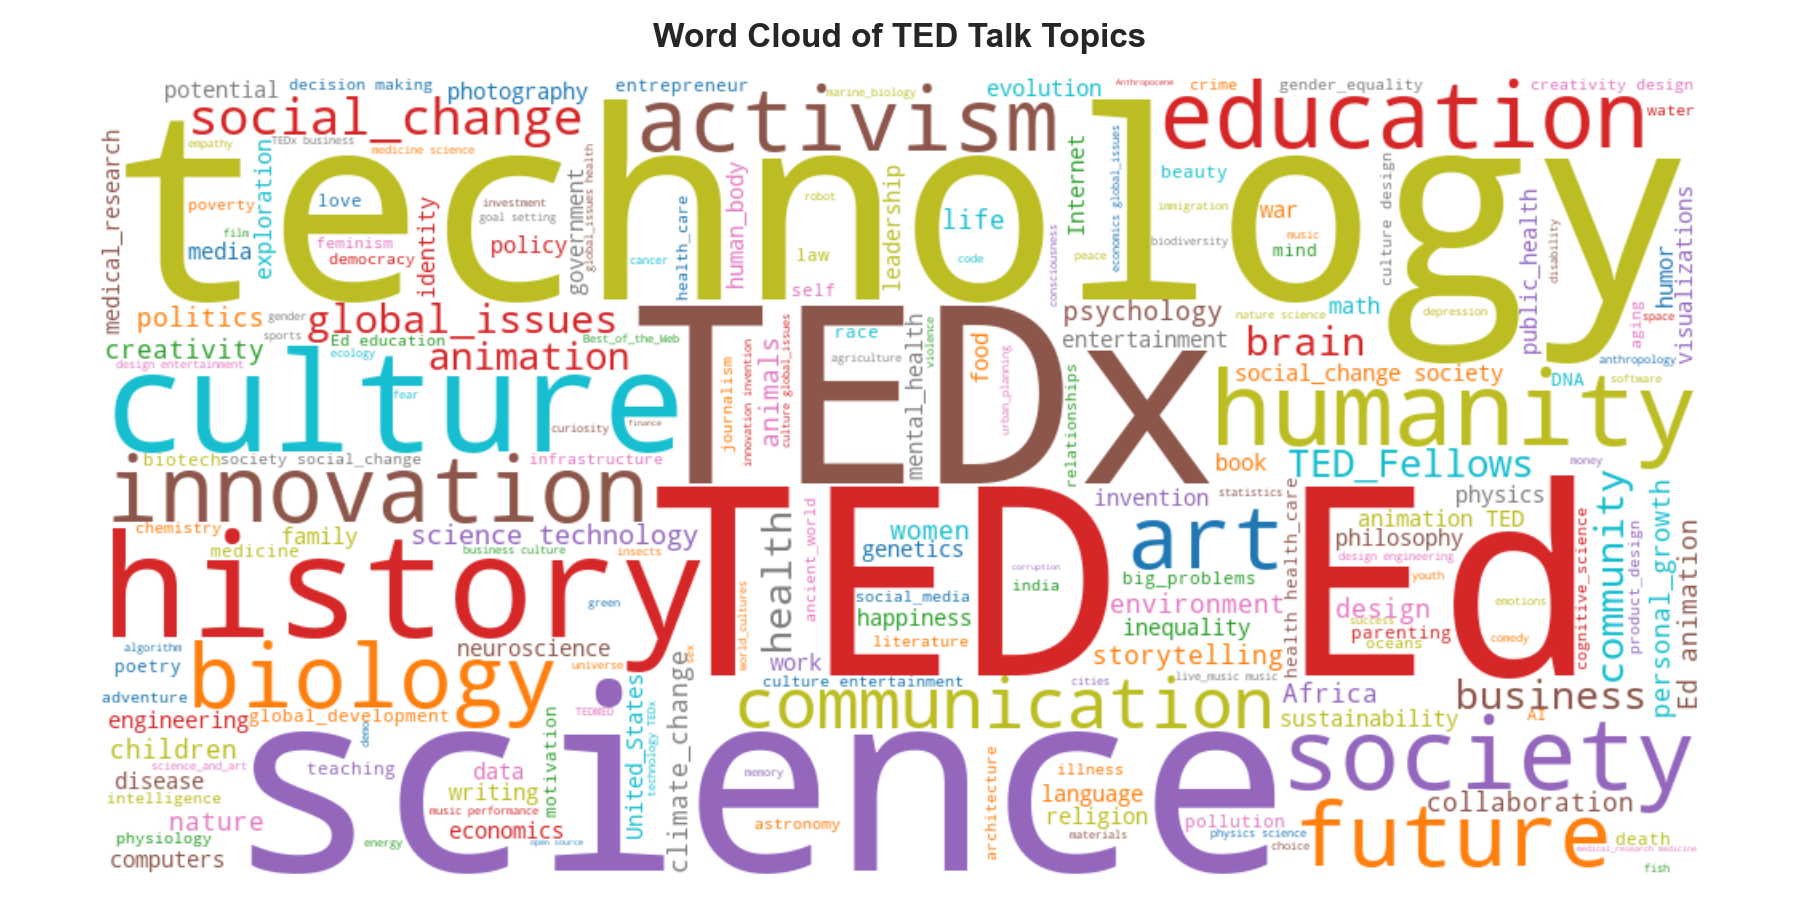

In [ ]:
# wordcloud of topics
text_topics = " ".join([t.replace(' ', '_') for t in all_topics])
wc = WordCloud(width=1000, height=500, background_color='white', colormap='tab10').generate(text_topics)
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of TED Talk Topics', fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## 7. Speech Characteristics & Correlation Analysis

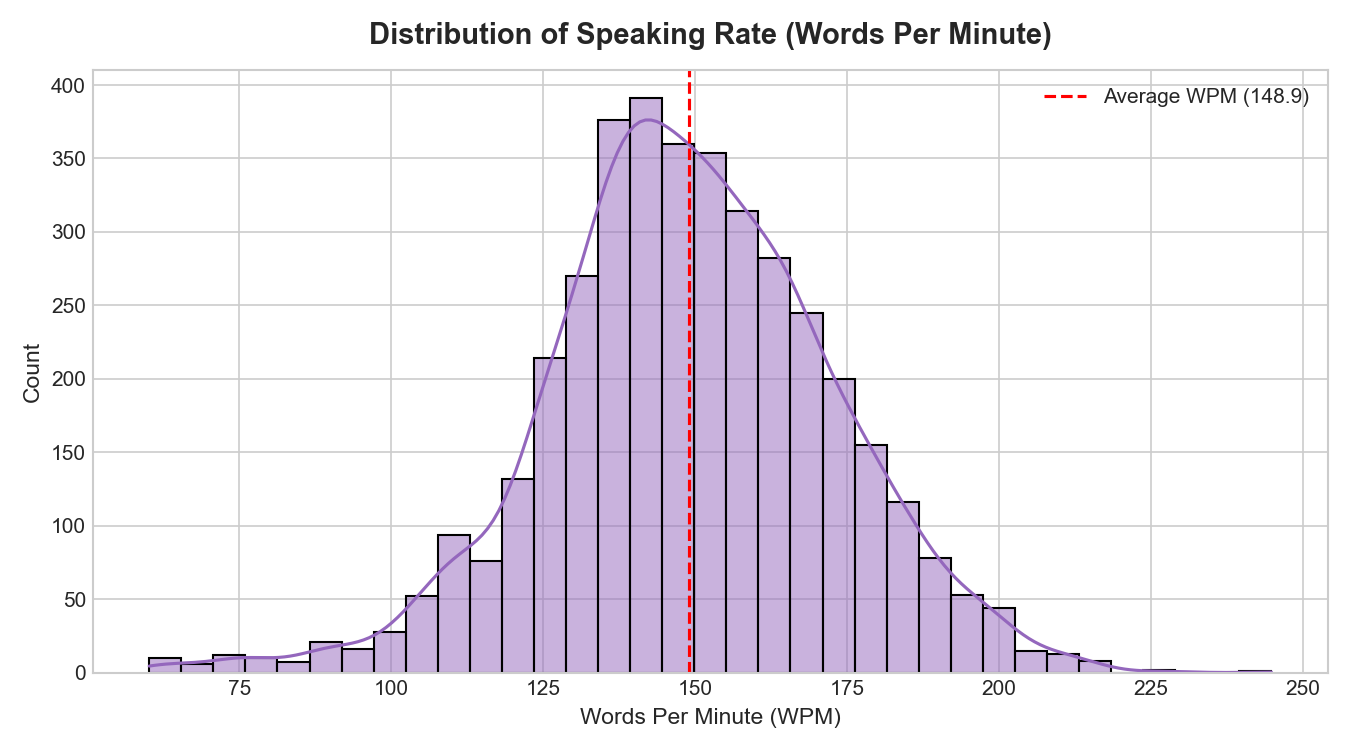

In [ ]:
# speaking rate wpm
valid_wpm = df[(df['speaking_rate_wpm'] >= 60) & (df['speaking_rate_wpm'] <= 260)]['speaking_rate_wpm']
plt.figure(figsize=(9, 5))
sns.histplot(valid_wpm, bins=35, kde=True, color='#9467bd')
plt.axvline(valid_wpm.mean(), color='red', linestyle='--', label=f'Mean WPM: {valid_wpm.mean():.1f}')
plt.title('Distribution of Speaking Rate (Words Per Minute)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Words Per Minute (WPM)')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

### Most Debated Talks (Comments per 1k Views)

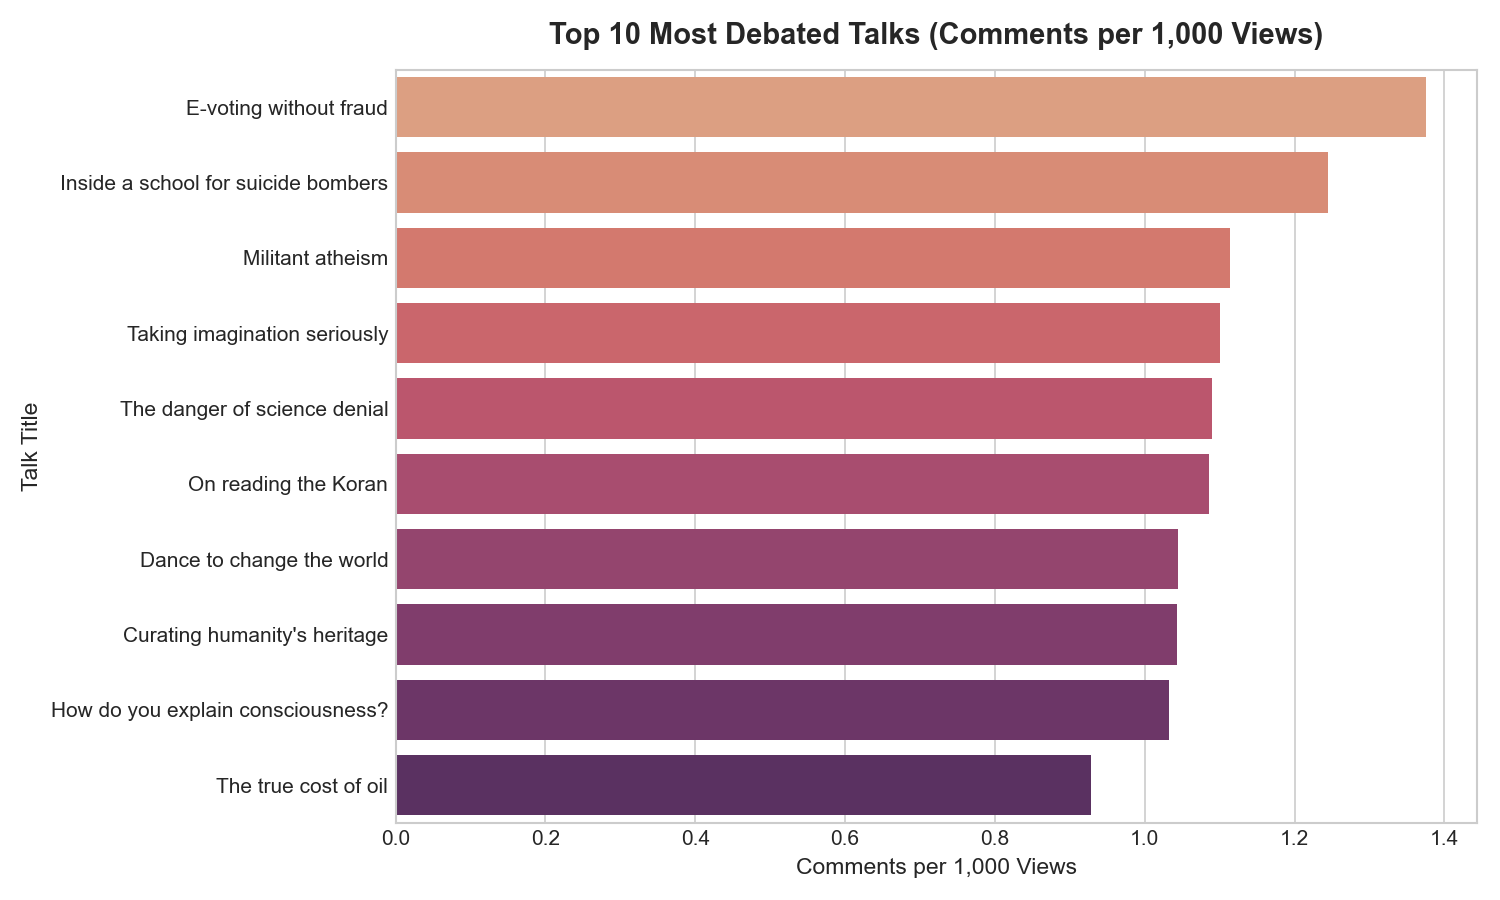

In [ ]:
# most debated talks
debated = df[df['views'] > 100000].sort_values(by='comments_per_1k_views', ascending=False).head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=debated, x='comments_per_1k_views', y='title', palette='flare')
plt.title('Top 10 Most Debated Talks (Comments per 1,000 Views)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Comments per 1,000 Views')
plt.ylabel('Talk Title')
plt.tight_layout()
plt.show()

### Available Languages Distribution

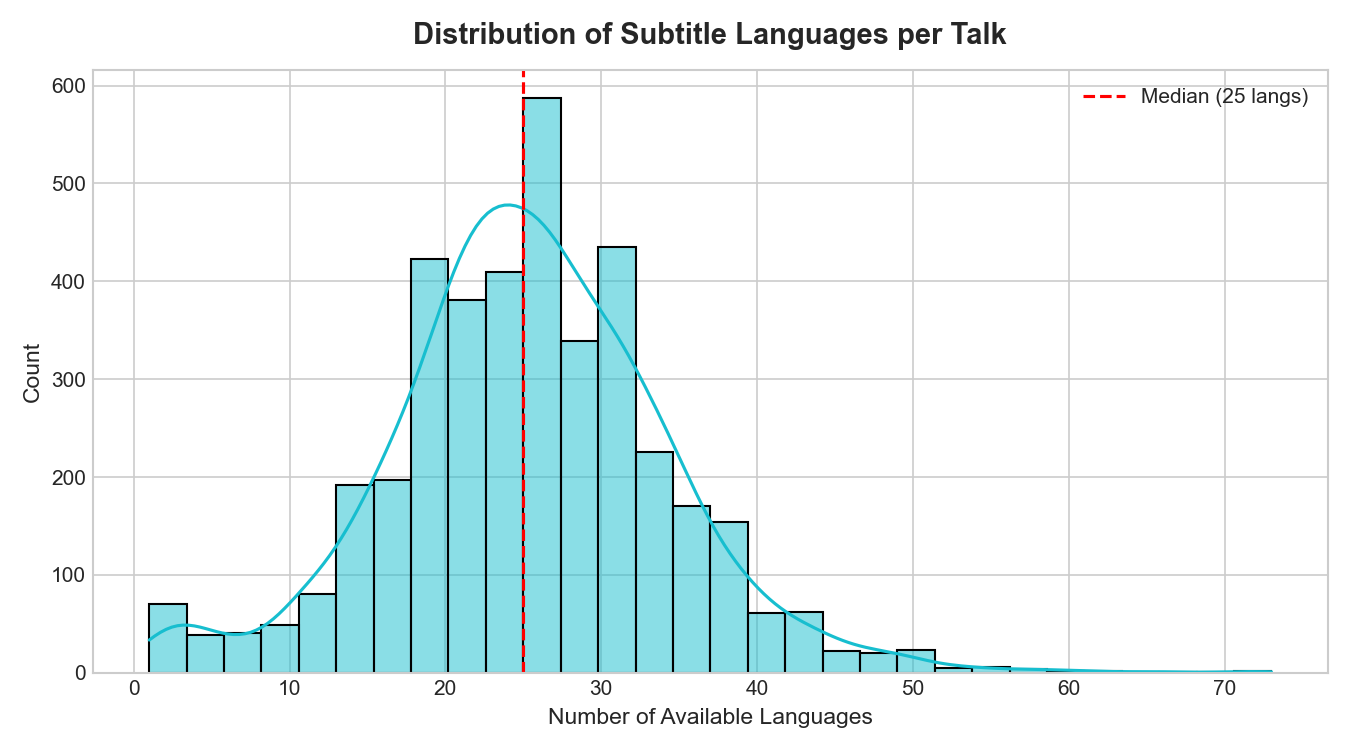

In [ ]:
# languages distribution
plt.figure(figsize=(9, 5))
sns.histplot(df['num_languages'], bins=30, kde=True, color='#17becf')
plt.axvline(df['num_languages'].median(), color='red', linestyle='--', label=f'Median: {df["num_languages"].median():.0f}')
plt.title('Distribution of Subtitle Languages per Talk', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Available Languages')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

### Feature Correlation Heatmap

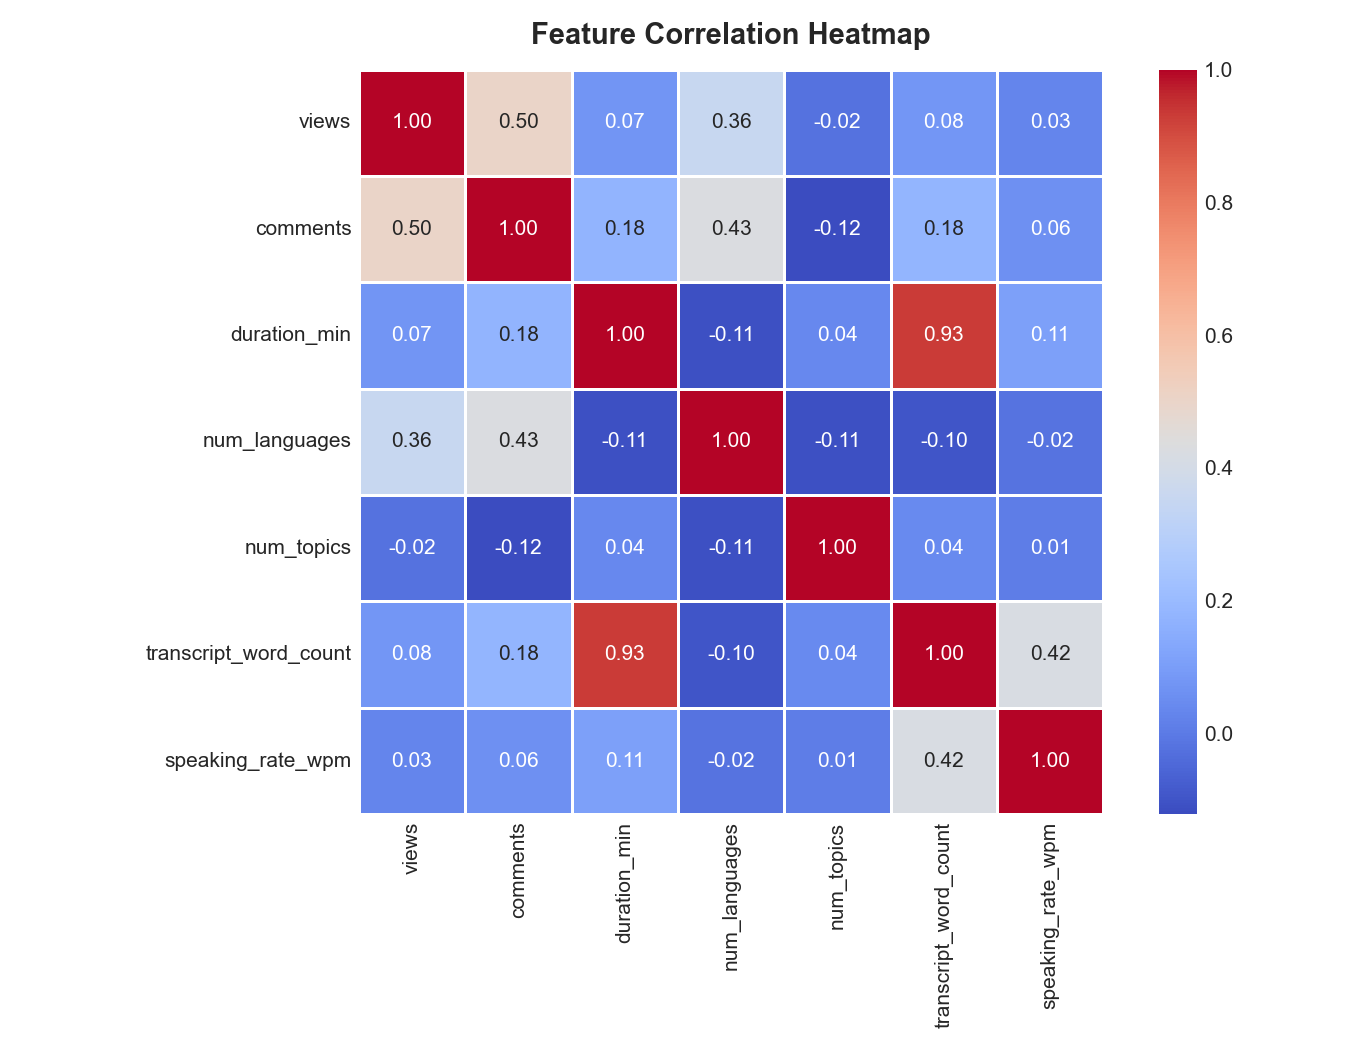

In [ ]:
# correlation heatmap
corr_cols = ['views', 'comments', 'duration_min', 'num_languages', 'num_topics', 'transcript_word_count', 'speaking_rate_wpm']
corr_matrix = df[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 8. Key Takeaways & Conclusions
1. **Viewership Skew:** Total views follow a Pareto-like distribution with a heavy right tail. The median is ~1.37M views, while outlier viral talks exceed 40-60M views.
2. **Talk Length Adherence:** Talks strictly respect TED's 18-minute guideline (median = 12.3 mins). A secondary spike exists at 3-5 minutes representing short format animations/ideas.
3. **Pace of Delivery:** Across thousands of speakers, the mean speaking rate is 147.4 WPM with normal distribution, showing speakers naturally calibrate to optimal comprehension speed.
4. **Publishing Cadence:** The TED content team primarily publishes between Tuesday and Thursday. Weekend releases are practically zero.
5. **Languages & Reach:** The number of translated subtitle languages shows a strong positive correlation with views ($r = 0.38$), proving that global translation drives international discoverability.
6. **Key Themes:** Science, Technology, Culture, and Global Issues remain the foundational pillars of TED's catalog.